In [64]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mistral_embeddings import ROOT, load_embeddings

embeddings, metadata = load_embeddings(ROOT / "data/embeddings/gospels")
meta = pd.DataFrame(metadata)
pd.set_option("display.max_colwidth", None)
embeddings.shape

(3779, 1024)

In [65]:
def verse_ticks(indices, n_ticks=6, offset=0):
    positions = np.unique(np.linspace(0, len(indices) - 1, min(n_ticks, len(indices)), dtype=int))
    verses = meta.iloc[indices[positions]]
    labels = [f"{v.chapter}:{v.verse}" for v in verses.itertuples()]
    return positions + 1 + offset, labels


In [83]:
def compute_top_n(similarities, threshold=0.90, fixed_n=None):
    if fixed_n is not None:
        if isinstance(fixed_n, bool) or not isinstance(fixed_n, (int, np.integer)) or fixed_n < 0:
            raise ValueError("fixed_n doit être un entier positif ou nul.")
        return int(fixed_n)
    if not -1 <= threshold <= 1:
        raise ValueError("threshold doit être compris entre -1 et 1.")
    return int(np.count_nonzero(np.asarray(similarities) >= threshold))


In [112]:
pair_x_book = "Matthieu"
pair_y_book = "Matthieu"

norms = np.linalg.norm(embeddings, axis=1, keepdims=True)
if not np.isfinite(embeddings).all() or np.any(norms == 0):
    raise ValueError("Les embeddings contiennent des valeurs invalides ou des vecteurs nuls.")
vectors = embeddings / norms

pair_x_indices = np.flatnonzero(meta["book_name"].eq(pair_x_book))
pair_y_indices = np.flatnonzero(meta["book_name"].eq(pair_y_book))
if not len(pair_x_indices) or not len(pair_y_indices):
    raise ValueError(f"Charger les embeddings complets de {pair_x_book} et {pair_y_book}.")

similarities = vectors[pair_y_indices] @ vectors[pair_x_indices].T
similarities.shape

(1071, 1071)

In [113]:
from_i = 0
to_i = 10

top = np.argsort(similarities.ravel())[::-1][from_i:to_i]
rows, cols = np.unravel_index(top, similarities.shape)

results = pd.DataFrame([
    {
        f"Référence {pair_y_book} (Y)": f"{meta.iloc[i]['chapter']}:{meta.iloc[i]['verse']}",
        f"Texte {pair_y_book} (Y)": meta.iloc[i]["text"],
        f"Référence {pair_x_book} (X)": f"{meta.iloc[j]['chapter']}:{meta.iloc[j]['verse']}",
        f"Texte {pair_x_book} (X)": meta.iloc[j]["text"],
        "Similarité": float(similarities[r, c]),
    }
    for r, c in zip(rows, cols)
    for i, j in [(pair_y_indices[r], pair_x_indices[c])]
])
results

,Référence Matthieu (Y),Texte Matthieu (Y),Référence Matthieu (X),Texte Matthieu (X),Similarité
0,2:10,"Quand ils aperçurent l'étoile, ils furent saisis d'une très grande joie.",2:10,"Quand ils aperçurent l'étoile, ils furent saisis d'une très grande joie.",1.000002
1,10:42,"Et quiconque donnera seulement un verre d'eau froide à l'un de ces petits parce qu'il est mon disciple, je vous le dis en vérité, il ne perdra point sa récompense.",10:42,"Et quiconque donnera seulement un verre d'eau froide à l'un de ces petits parce qu'il est mon disciple, je vous le dis en vérité, il ne perdra point sa récompense.",1.000002
2,27:30,"Et ils crachaient contre lui, prenaient le roseau, et frappaient sur sa tête.",27:30,"Et ils crachaient contre lui, prenaient le roseau, et frappaient sur sa tête.",1.000002
3,28:2,"Et voici, il y eut un grand tremblement de terre; car un ange du Seigneur descendit du ciel, vint rouler la pierre, et s'assit dessus.",28:2,"Et voici, il y eut un grand tremblement de terre; car un ange du Seigneur descendit du ciel, vint rouler la pierre, et s'assit dessus.",1.000002
4,16:1,"¶ Les pharisiens et les sadducéens abordèrent Jésus et, pour l'éprouver, lui demandèrent de leur faire voir un signe venant du ciel.",16:1,"¶ Les pharisiens et les sadducéens abordèrent Jésus et, pour l'éprouver, lui demandèrent de leur faire voir un signe venant du ciel.",1.000001
5,5:29,"Si ton oeil droit est pour toi une occasion de chute, arrache-le et jette-le loin de toi; car il est avantageux pour toi qu'un seul de tes membres périsse, et que ton corps entier ne soit pas jeté dans la géhenne.",5:29,"Si ton oeil droit est pour toi une occasion de chute, arrache-le et jette-le loin de toi; car il est avantageux pour toi qu'un seul de tes membres périsse, et que ton corps entier ne soit pas jeté dans la géhenne.",1.000001
6,17:12,"Mais je vous dis qu'Elie est déjà venu, qu'ils ne l'ont pas reconnu, et qu'ils l'ont traité comme ils ont voulu. De même le Fils de l'homme souffrira de leur part.",17:12,"Mais je vous dis qu'Elie est déjà venu, qu'ils ne l'ont pas reconnu, et qu'ils l'ont traité comme ils ont voulu. De même le Fils de l'homme souffrira de leur part.",1.000001
7,12:45,"Il s'en va, et il prend avec lui sept autres esprits plus méchants que lui; ils entrent dans la maison, s'y établissent, et la dernière condition de cet homme est pire que la première. Il en sera de même pour cette génération méchante.",12:45,"Il s'en va, et il prend avec lui sept autres esprits plus méchants que lui; ils entrent dans la maison, s'y établissent, et la dernière condition de cet homme est pire que la première. Il en sera de même pour cette génération méchante.",1.000001
8,20:33,"Ils lui dirent: Seigneur, que nos yeux s'ouvrent.",20:33,"Ils lui dirent: Seigneur, que nos yeux s'ouvrent.",1.000001
9,18:21,"¶ Alors Pierre s'approcha de lui, et dit: Seigneur, combien de fois pardonnerai-je à mon frère, lorsqu'il péchera contre moi? Sera-ce jusqu'à sept fois?",18:21,"¶ Alors Pierre s'approcha de lui, et dit: Seigneur, combien de fois pardonnerai-je à mon frère, lorsqu'il péchera contre moi? Sera-ce jusqu'à sept fois?",1.000001


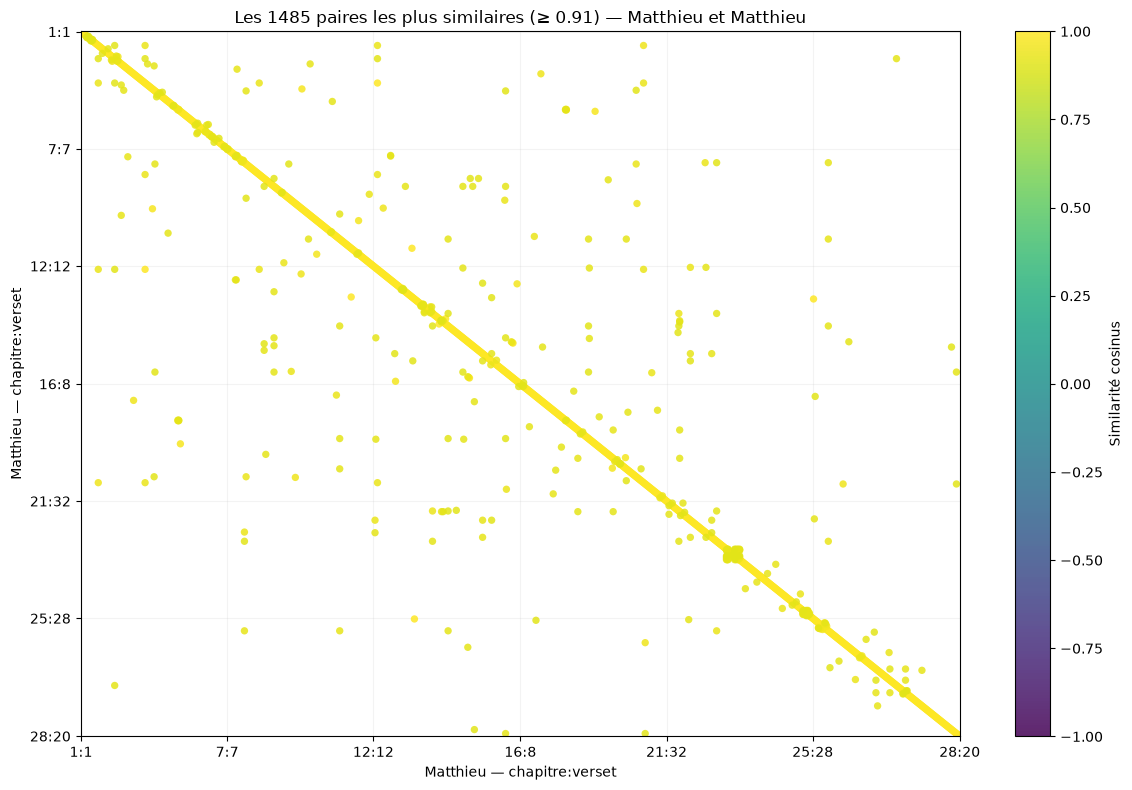

In [117]:
threshold = 0.91
top_n = compute_top_n(similarities, threshold=threshold, fixed_n=None)

if not isinstance(top_n, int) or not 1 <= top_n <= similarities.size:
    raise ValueError(f"top_n doit être compris entre 1 et {similarities.size}.")

scatter_top = np.argsort(similarities.ravel())[-top_n:][::-1]
scatter_rows, scatter_cols = np.unravel_index(scatter_top, similarities.shape)
scatter_scores = similarities[scatter_rows, scatter_cols]

fig, ax = plt.subplots(figsize=(12, 8))
points = ax.scatter(
    scatter_cols + 1,
    scatter_rows + 1,
    c=scatter_scores,
    cmap="viridis",
    vmin=-1,
    vmax=1,
    s=28,
    alpha=0.85,
    edgecolors="none",
)
ax.set_xlim(0.5, len(pair_x_indices) + 0.5)
ax.set_ylim(len(pair_y_indices) + 0.5, 0.5)
ax.set_xticks(*verse_ticks(pair_x_indices, n_ticks=7))
ax.set_yticks(*verse_ticks(pair_y_indices, n_ticks=7))
ax.set_xlabel(f"{pair_x_book} — chapitre:verset")
ax.set_ylabel(f"{pair_y_book} — chapitre:verset")
ax.set_title(f"Les {top_n} paires les plus similaires (≥ {threshold}) — {pair_y_book} et {pair_x_book}")
ax.grid(alpha=0.15)
ax.set_axisbelow(True)
fig.colorbar(points, ax=ax, label="Similarité cosinus")
fig.tight_layout()
plt.show()

In [96]:
(ROOT / "imgs").mkdir(exist_ok=True)
fig.savefig(ROOT / "imgs" / f"{pair_y_book}_{pair_x_book}_similarity.png", dpi=300, bbox_inches="tight")

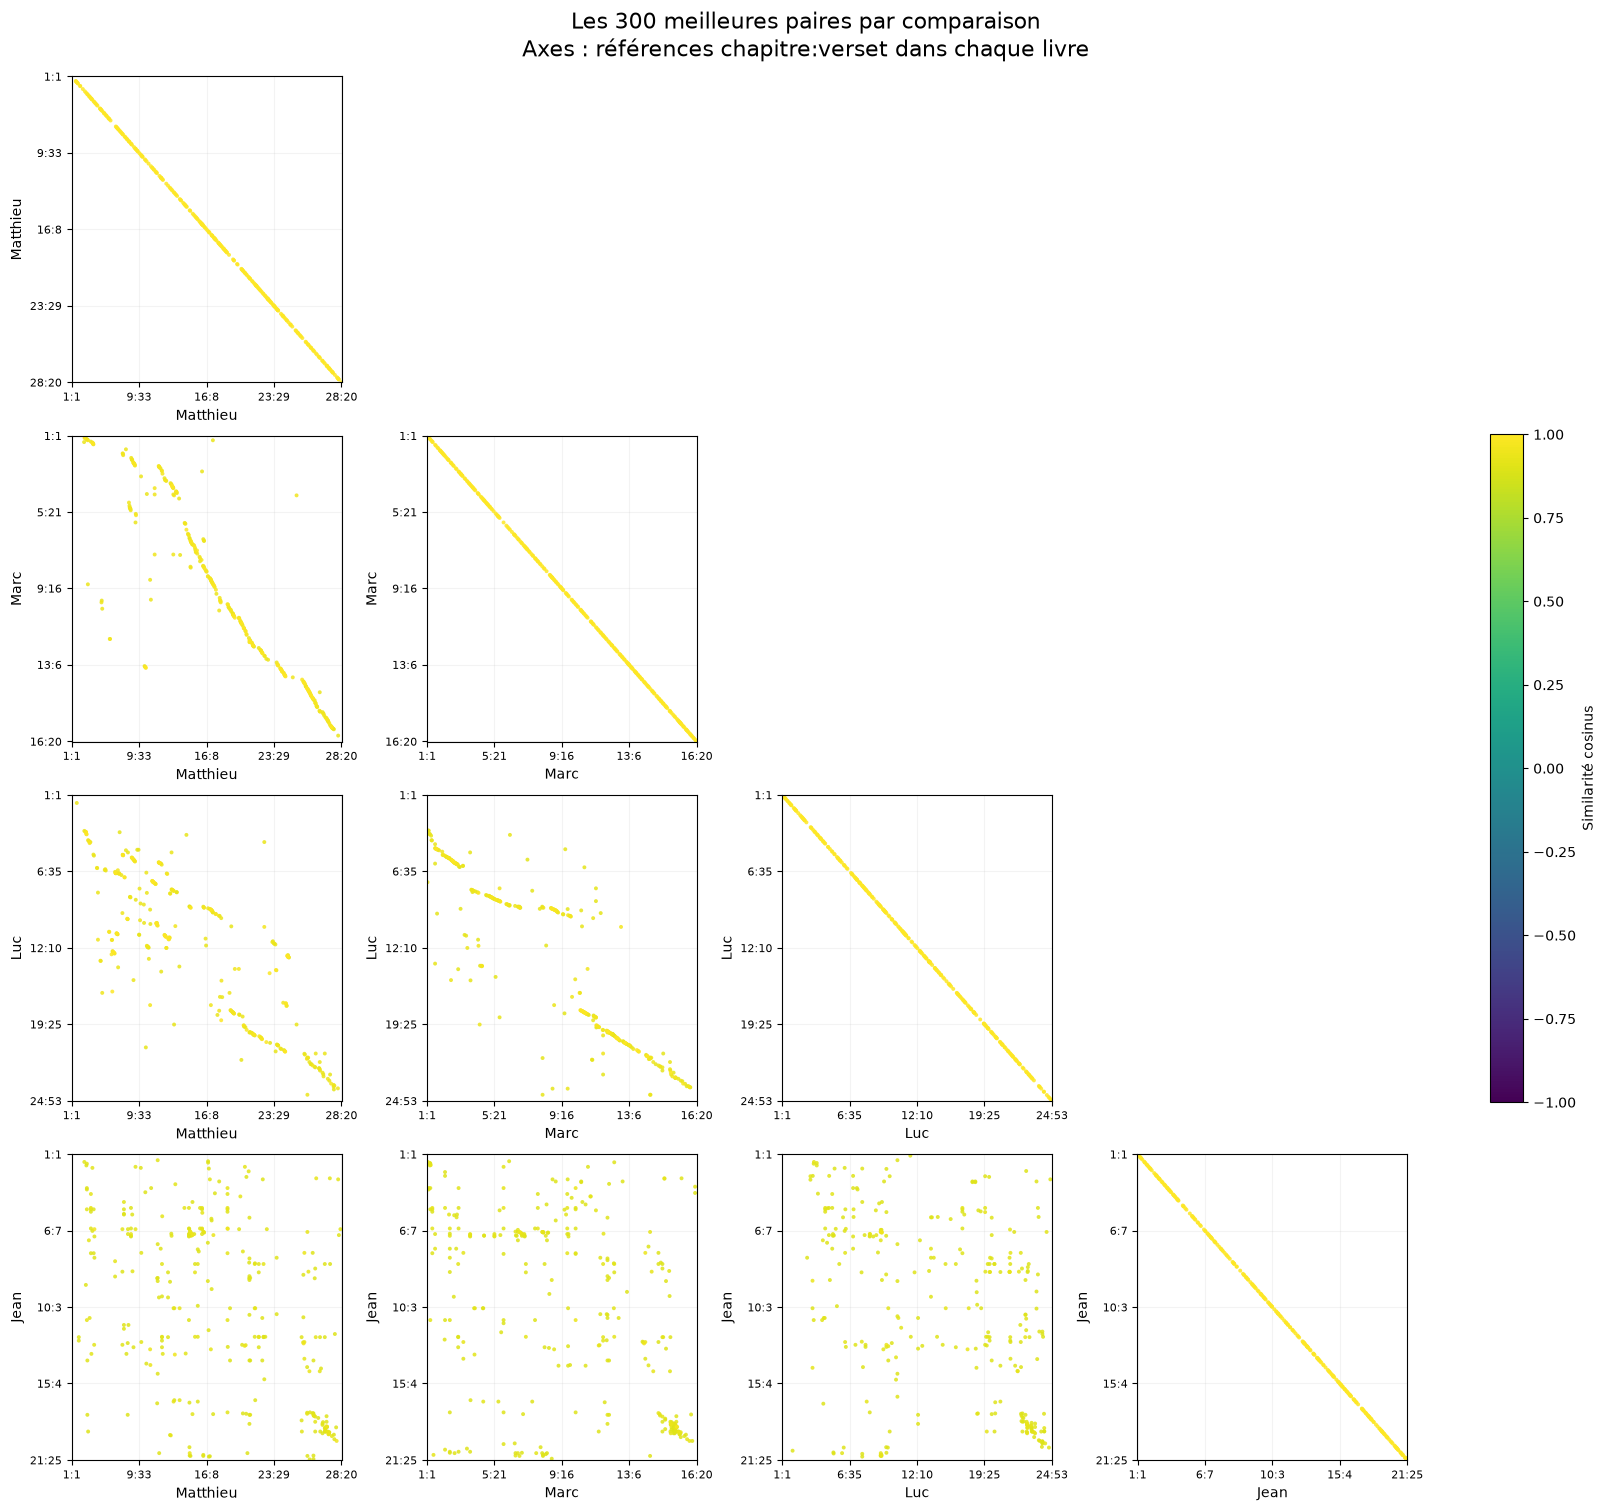

In [100]:
top_n = 300
hide_same_book = False

books = ["Matthieu", "Marc", "Luc", "Jean"]
book_indices = {
    book: np.flatnonzero(meta["book_name"].eq(book))
    for book in books
}
if any(len(indices) == 0 for indices in book_indices.values()):
    raise ValueError("Charger les embeddings des quatre Évangiles.")
if not isinstance(top_n, int) or top_n < 1:
    raise ValueError("top_n doit être un entier positif.")

row_books = books[1:] if hide_same_book else books
col_books = books[:-1] if hide_same_book else books

fig_grid, axes_grid = plt.subplots(
    len(row_books), len(col_books),
    figsize=(13, 12) if hide_same_book else (16, 15),
    layout="constrained",
)
for row_index, y_book in enumerate(row_books):
    for col_index, x_book in enumerate(col_books):
        grid_ax = axes_grid[row_index, col_index]
        if col_index > row_index:
            grid_ax.set_axis_off()
            continue

        y_indices = book_indices[y_book]
        x_indices = book_indices[x_book]
        pair_similarities = vectors[y_indices] @ vectors[x_indices].T
        pair_count = min(top_n, pair_similarities.size)
        pair_top = np.argsort(pair_similarities.ravel())[-pair_count:]
        pair_rows, pair_cols = np.unravel_index(pair_top, pair_similarities.shape)

        grid_ax.scatter(
            pair_cols + 1,
            pair_rows + 1,
            c=pair_similarities[pair_rows, pair_cols],
            cmap="viridis", vmin=-1, vmax=1,
            s=8, alpha=0.85, edgecolors="none",
        )
        grid_ax.set_xlim(0.5, len(x_indices) + 0.5)
        grid_ax.set_ylim(len(y_indices) + 0.5, 0.5)
        grid_ax.set_xticks(*verse_ticks(x_indices, n_ticks=5))
        grid_ax.set_yticks(*verse_ticks(y_indices, n_ticks=5))
        grid_ax.set_xlabel(x_book)
        grid_ax.set_ylabel(y_book)
        grid_ax.tick_params(labelsize=8)
        grid_ax.grid(alpha=0.15)
        grid_ax.set_axisbelow(True)

fig_grid.suptitle(
    f"Les {top_n} meilleures paires par comparaison\n"
    "Axes : références chapitre:verset dans chaque livre",
    fontsize=16,
)
fig_grid.colorbar(
    plt.cm.ScalarMappable(norm=plt.Normalize(-1, 1), cmap="viridis"),
    ax=axes_grid.ravel().tolist(),
    label="Similarité cosinus", shrink=0.75, fraction=0.025,
)
plt.show()

In [101]:
fig_grid.savefig(ROOT / "imgs" / "four_gospels_similarity_diag.png", dpi=300, bbox_inches="tight")

In [33]:
from IPython.display import display

zone_x_book = "Marc"
zone_y_book = "Jean"
zone_top_n = 300
x_bounds = (550, 678)
y_bounds = (740, 830)

zone_x_indices = np.flatnonzero(meta["book_name"].eq(zone_x_book))
zone_y_indices = np.flatnonzero(meta["book_name"].eq(zone_y_book))
if not len(zone_x_indices) or not len(zone_y_indices):
    raise ValueError("Livre absent des métadonnées.")
if not isinstance(zone_top_n, int) or zone_top_n < 1:
    raise ValueError("zone_top_n doit être un entier positif.")
if not (1 <= x_bounds[0] <= x_bounds[1] <= len(zone_x_indices)):
    raise ValueError("Bornes X invalides : positions à partir de 1, bornes incluses.")
if not (1 <= y_bounds[0] <= y_bounds[1] <= len(zone_y_indices)):
    raise ValueError("Bornes Y invalides : positions à partir de 1, bornes incluses.")

zone_similarities = vectors[zone_y_indices] @ vectors[zone_x_indices].T
zone_top = np.argsort(zone_similarities.ravel())[-min(zone_top_n, zone_similarities.size):][::-1]
zone_rows, zone_cols = np.unravel_index(zone_top, zone_similarities.shape)
zone_mask = (
    (zone_cols + 1 >= x_bounds[0]) & (zone_cols + 1 <= x_bounds[1])
    & (zone_rows + 1 >= y_bounds[0]) & (zone_rows + 1 <= y_bounds[1])
)
zone_rows, zone_cols = zone_rows[zone_mask], zone_cols[zone_mask]

zone_records = []
for r, c in zip(zone_rows, zone_cols):
    x_verse = meta.iloc[zone_x_indices[c]]
    y_verse = meta.iloc[zone_y_indices[r]]
    zone_records.append({
        "Position X": int(c + 1),
        "Référence X": f"{zone_x_book} {x_verse['chapter']}:{x_verse['verse']}",
        "Texte X": x_verse["text"],
        "Position Y": int(r + 1),
        "Référence Y": f"{zone_y_book} {y_verse['chapter']}:{y_verse['verse']}",
        "Texte Y": y_verse["text"],
        "Similarité": float(zone_similarities[r, c]),
    })
zone_results = pd.DataFrame(zone_records, columns=[
    "Position X", "Référence X", "Texte X",
    "Position Y", "Référence Y", "Texte Y", "Similarité",
])
print(f"{len(zone_results)} paires dans la zone, parmi les {zone_top_n} meilleures du couple.")
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(zone_results)


57 paires dans la zone, parmi les 300 meilleures du couple.


,Position X,Référence X,Texte X,Position Y,Référence Y,Texte Y,Similarité
0,628,Marc 15:17,"Ils le revêtirent de pourpre, et posèrent sur sa tête une couronne d'épines, qu'ils avaient tressée.",783,Jean 19:2,"Les soldats tressèrent une couronne d'épines qu'ils posèrent sur sa tête, et ils le revêtirent d'un manteau de pourpre; puis, s'approchant de lui,",0.963987
1,613,Marc 15:2,Pilate l'interrogea: Es-tu le roi des Juifs? Jésus lui répondit: Tu le dis.,774,Jean 18:33,"Pilate rentra dans le prétoire, appela Jésus, et lui dit: Es-tu le roi des Juifs?",0.944684
2,629,Marc 15:18,"Puis ils se mirent à le saluer: Salut, roi des Juifs!",784,Jean 19:3,"ils disaient: Salut, roi des Juifs! Et ils lui donnaient des soufflets.",0.940317
3,633,Marc 15:22,"¶ et ils conduisirent Jésus au lieu nommé Golgotha, ce qui signifie lieu du crâne.",798,Jean 19:17,"Jésus, portant sa croix, arriva au lieu du crâne, qui se nomme en hébreu Golgotha.",0.935761
4,613,Marc 15:2,Pilate l'interrogea: Es-tu le roi des Juifs? Jésus lui répondit: Tu le dis.,778,Jean 18:37,"Pilate lui dit: Tu es donc roi? Jésus répondit: Tu le dis, je suis roi. Je suis né et je suis venu dans le monde pour rendre témoignage à la vérité. Quiconque est de la vérité écoute ma voix.",0.935067
5,638,Marc 15:27,"Ils crucifièrent avec lui deux brigands, l'un à sa droite, et l'autre à sa gauche.",799,Jean 19:18,"C'est là qu'il fut crucifié, et deux autres avec lui, un de chaque côté, et Jésus au milieu.",0.928733
6,654,Marc 15:43,"arriva Joseph d'Arimathée, conseiller de distinction, qui lui-même attendait aussi le royaume de Dieu. Il osa se rendre vers Pilate, pour demander le corps de Jésus.",819,Jean 19:38,"¶ Après cela, Joseph d'Arimathée, qui était disciple de Jésus, mais en secret par crainte des Juifs, demanda à Pilate la permission de prendre le corps de Jésus. Et Pilate le permit. Il vint donc, et prit le corps de Jésus.",0.928009
7,625,Marc 15:14,Pilate leur dit: Quel mal a-t-il fait? Et ils crièrent encore plus fort: Crucifie-le!,787,Jean 19:6,"Lorsque les principaux sacrificateurs et les huissiers le virent, ils s'écrièrent: Crucifie! crucifie! Pilate leur dit: Prenez-le vous-mêmes, et crucifiez-le; car moi, je ne trouve point de crime en lui.",0.927666
8,660,Marc 16:2,"Le premier jour de la semaine, elles se rendirent au sépulcre, de grand matin, comme le soleil venait de se lever.",824,Jean 20:1,"¶ Le premier jour de la semaine, Marie de Magdala se rendit au sépulcre dès le matin, comme il faisait encore obscur; et elle vit que la pierre était ôtée du sépulcre.",0.925133
9,623,Marc 15:12,"Pilate, reprenant la parole, leur dit: Que voulez-vous donc que je fasse de celui que vous appelez le roi des Juifs?",774,Jean 18:33,"Pilate rentra dans le prétoire, appela Jésus, et lui dit: Es-tu le roi des Juifs?",0.924647


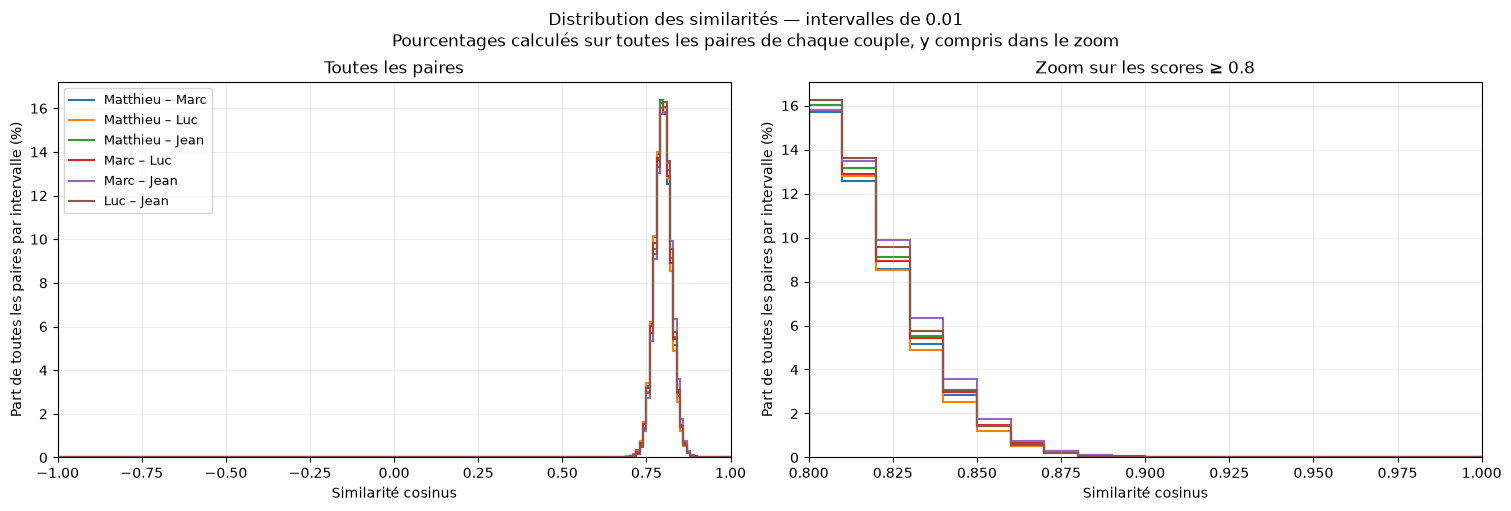

In [34]:
from itertools import combinations

n_bins = 200
zoom_min = 0.80

if not isinstance(n_bins, int) or n_bins < 1:
    raise ValueError("n_bins doit être un entier positif.")
if not -1 <= zoom_min < 1:
    raise ValueError("zoom_min doit être compris entre -1 inclus et 1 exclu.")

dist_books = ["Matthieu", "Marc", "Luc", "Jean"]
dist_indices = {
    book: np.flatnonzero(meta["book_name"].eq(book))
    for book in dist_books
}
if any(len(indices) == 0 for indices in dist_indices.values()):
    raise ValueError("Charger les embeddings des quatre Évangiles.")

bin_edges = np.linspace(-1, 1, n_bins + 1)
zoom_start = max(0, np.searchsorted(bin_edges, zoom_min, side="right") - 1)
fig_dist, axes_dist = plt.subplots(1, 2, figsize=(15, 5), layout="constrained")

for dist_a, dist_b in combinations(dist_books, 2):
    dist_scores = vectors[dist_indices[dist_a]] @ vectors[dist_indices[dist_b]].T
    dist_scores = np.clip(dist_scores.ravel(), -1, 1)
    counts, _ = np.histogram(dist_scores, bins=bin_edges)
    percentages = 100 * counts / dist_scores.size
    label = f"{dist_a} – {dist_b}"
    axes_dist[0].stairs(percentages, bin_edges, label=label, linewidth=1.5)
    axes_dist[1].stairs(
        percentages[zoom_start:], bin_edges[zoom_start:],
        label=label, linewidth=1.5,
    )

axes_dist[0].set_xlim(-1, 1)
axes_dist[0].set_title("Toutes les paires")
axes_dist[1].set_xlim(zoom_min, 1)
axes_dist[1].set_title(f"Zoom sur les scores ≥ {zoom_min:g}")
for dist_ax in axes_dist:
    dist_ax.set_xlabel("Similarité cosinus")
    dist_ax.set_ylabel("Part de toutes les paires par intervalle (%)")
    dist_ax.set_ylim(bottom=0)
    dist_ax.grid(alpha=0.2)
axes_dist[0].legend(fontsize=9)
fig_dist.suptitle(
    f"Distribution des similarités — intervalles de {2 / n_bins:g}\n"
    "Pourcentages calculés sur toutes les paires de chaque couple, y compris dans le zoom"
)
plt.show()

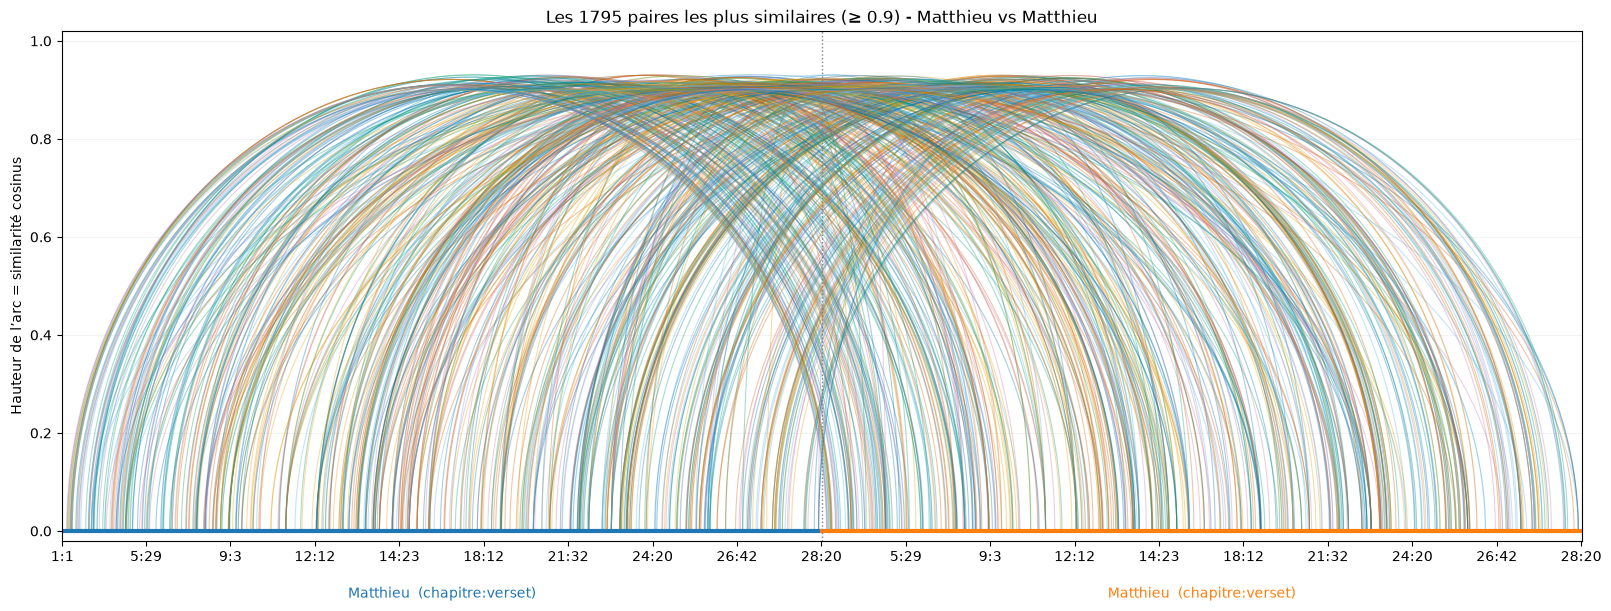

In [122]:
from matplotlib.collections import LineCollection

arc_palette = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#D55E00", "#56B4E9"]
arc_seed = 42

threshold = 0.9
fixed_n = None
left_book = "Matthieu"
right_book = "Matthieu"

arc_left_indices = np.flatnonzero(meta["book_name"].eq(left_book))
arc_right_indices = np.flatnonzero(meta["book_name"].eq(right_book))
if not len(arc_left_indices) or not len(arc_right_indices):
    raise ValueError(f"Charger les embeddings de {left_book} et {right_book}.")
arc_similarities = vectors[arc_left_indices] @ vectors[arc_right_indices].T
top_n = compute_top_n(arc_similarities, threshold=threshold, fixed_n=fixed_n)
if top_n > arc_similarities.size:
    raise ValueError(f"fixed_n ne peut pas dépasser {arc_similarities.size}.")

arc_top = (
    #np.argsort(arc_similarities.ravel())[-top_n:]
    np.argsort(similarities.ravel())[::-1][1200:top_n]
    if top_n else np.empty(0, dtype=int)
)
arc_rows, arc_cols = np.unravel_index(arc_top, arc_similarities.shape)
arc_scores = np.clip(arc_similarities[arc_rows, arc_cols], -1, 1)
arc_left_count = len(arc_left_indices)
arc_right_count = len(arc_right_indices)
arc_starts = arc_rows + 1
arc_ends = arc_left_count + arc_cols + 1
arc_centers = (arc_starts + arc_ends) / 2
arc_radii = (arc_ends - arc_starts) / 2
arc_theta = np.linspace(np.pi, 0, 201)

arc_segments = [
    np.column_stack((
        center + radius * np.cos(arc_theta),
        score * np.sin(arc_theta),
    ))
    for center, radius, score in zip(arc_centers, arc_radii, arc_scores)
]
arc_rng = np.random.default_rng(arc_seed)
arc_colors = arc_rng.choice(arc_palette, size=len(arc_segments))

fig_arcs, ax_arcs = plt.subplots(figsize=(16, 6), layout="constrained")
ax_arcs.add_collection(LineCollection(
    arc_segments, colors=arc_colors, linewidths=0.8, alpha=0.35,
))
ax_arcs.plot([1, arc_left_count], [0, 0], color="tab:blue", linewidth=3)
ax_arcs.plot(
    [arc_left_count + 1, arc_left_count + arc_right_count], [0, 0],
    color="tab:orange", linewidth=3,
)
ax_arcs.axvline(arc_left_count + 0.5, color="grey", linestyle=":", linewidth=1)
ax_arcs.set_xlim(0, arc_left_count + arc_right_count + 1)
ax_arcs.set_ylim(min(0, float(arc_scores.min(initial=0))) - 0.02, 1.02)

arc_left_ticks, arc_left_labels = verse_ticks(arc_left_indices,n_ticks=10)
arc_right_ticks, arc_right_labels = verse_ticks(arc_right_indices,n_ticks=10, offset=arc_left_count)
ax_arcs.set_xticks(
    np.r_[arc_left_ticks, arc_right_ticks[1:]],
    labels=arc_left_labels + arc_right_labels[1:],
)
ax_arcs.text(
    (1 + arc_left_count) / 2, -0.09, f"{left_book}  (chapitre:verset)",
    transform=ax_arcs.get_xaxis_transform(), ha="center", va="top", color="tab:blue",
)
ax_arcs.text(
    arc_left_count + (1 + arc_right_count) / 2, -0.09, f"{right_book}  (chapitre:verset)",
    transform=ax_arcs.get_xaxis_transform(), ha="center", va="top", color="tab:orange",
)
ax_arcs.set_ylabel("Hauteur de l’arc = similarité cosinus")
ax_arcs.set_title(
    f"Les {top_n} paires les plus similaires"
    + (f" (≥ {threshold:g})" if fixed_n is None else "")
    + f" - {left_book} vs {right_book}"
)
ax_arcs.grid(axis="y", alpha=0.15)
ax_arcs.set_axisbelow(True)
plt.show()

In [77]:
(ROOT / "imgs").mkdir(exist_ok=True)
fig_arcs.savefig(
    ROOT / "imgs" / f"arcs_{left_book}_{right_book}.png",
    dpi=300,
    bbox_inches="tight",
)